In [2]:
import pandas as pd
import seaborn as sns

In [4]:
# Save the cleaned dataset
dataset=pd.read_csv("Elevator_predictive_maintenance_cleaned.csv")

In [5]:
dataset

,Motor_Temperature_C,Motor_Vibration_mm_s,Motor_Current_A,Motor_Speed_RPM,Brake_Temperature_C,Door_Opening_Time_s,Door_Closing_Time_s,Load_Percentage,Number_of_Trips,Operating_Hours,Error_Count,Days_Since_Maintenance,Previous_Faults,Maintenance_Required
0,94.56,1.84,20.15,1470.3,57.150000,2.91,3.09,70.42,83.000000,2889.6,5.0,224.3,3.0,0.0
1,105.00,4.27,20.10,1420.8,84.050000,3.83,4.28,49.96,192.000000,7276.7,13.0,602.8,7.0,1.0
2,67.60,1.64,19.80,1471.1,46.360000,2.23,2.96,80.75,31.000000,1082.3,1.0,101.4,1.0,0.0
3,105.00,4.24,13.63,1443.8,80.730000,3.33,3.75,29.09,111.492723,6716.5,12.0,575.6,9.0,1.0
4,92.52,2.13,18.64,1466.5,62.520000,3.11,3.06,56.64,105.000000,3116.7,4.0,281.1,2.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
480,75.25,2.01,18.61,1488.1,44.030000,2.26,2.65,72.45,36.000000,1156.6,2.0,76.5,1.0,0.0
481,99.81,2.98,16.39,1456.0,54.790000,3.34,2.72,74.99,40.000000,2621.0,7.0,173.2,2.0,0.0
482,99.31,2.66,19.45,1443.8,65.636737,2.67,2.94,47.38,76.000000,3639.4,4.0,256.4,2.0,0.0
483,85.15,2.41,14.90,1470.0,56.170000,2.73,2.83,40.67,41.000000,2693.9,8.0,218.3,4.0,0.0


In [6]:
dataset.isnull().sum()

Motor_Temperature_C       0
Motor_Vibration_mm_s      0
Motor_Current_A           0
Motor_Speed_RPM           0
Brake_Temperature_C       0
Door_Opening_Time_s       0
Door_Closing_Time_s       0
Load_Percentage           0
Number_of_Trips           0
Operating_Hours           0
Error_Count               0
Days_Since_Maintenance    0
Previous_Faults           0
Maintenance_Required      0
dtype: int64

# probability

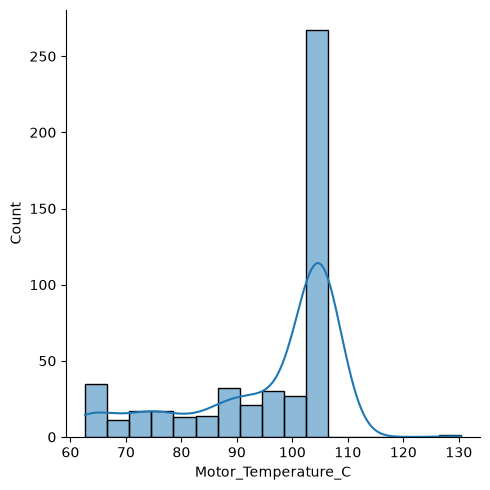

In [7]:
sns.displot(dataset["Motor_Temperature_C"],kde=True)

In [8]:
def get_pdf_probability(dataset,startrange,endrange):
    from matplotlib import pyplot
    from scipy.stats import norm
    import seaborn as sns
    ax = sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')
    pyplot.axvline(startrange,color='Red')
    pyplot.axvline(endrange,color='Red')
    # generate a sample
    sample = dataset
    # calculate parameters
    sample_mean =sample.mean()
    sample_std = sample.std()
    print('Mean=%.3f, Standard Deviation=%.3f' % (sample_mean, sample_std))
    # define the distribution
    dist = norm(sample_mean, sample_std)
    
    # sample probabilities for a range of outcomes
    values = [value for value in range(startrange, endrange)]
    probabilities = [dist.pdf(value) for value in values]    
    prob=sum(probabilities)
    print("The area between range({},{}):{}".format(startrange,endrange,sum(probabilities)))
    return prob

Mean=95.413, Standard Deviation=13.664
The area between range(100,110):0.2311854060406831


C:\Users\User\AppData\Local\Temp\ipykernel_10752\132380739.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax = sns.distplot(dataset,kde=True,kde_kws={'color':'blue'},color='Green')


np.float64(0.2311854060406831)

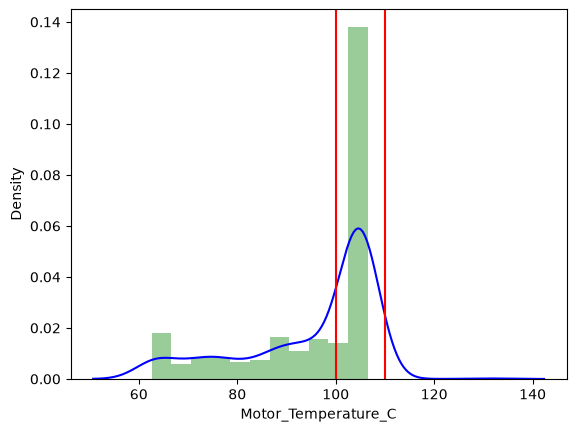

In [10]:
get_pdf_probability(dataset["Motor_Temperature_C"],100,110)

In [11]:
from statsmodels.distributions.empirical_distribution import ECDF
ecdf = ECDF(dataset['Motor_Temperature_C'])
ecdf(80)

np.float64(0.1731958762886598)

In [12]:
def stdNBgraph(dataset):
        # Coverted to standard Normal Distribution
    import seaborn as sns
    mean=dataset.mean()
    std=dataset.std()

    values=[i for i in dataset]

    z_score=[((j-mean)/std) for j in values]

    sns.distplot(z_score,kde=True)

    sum(z_score)/len(z_score)
    #z_score.std()

C:\Users\User\AppData\Local\Temp\ipykernel_10752\4109782476.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(z_score,kde=True)


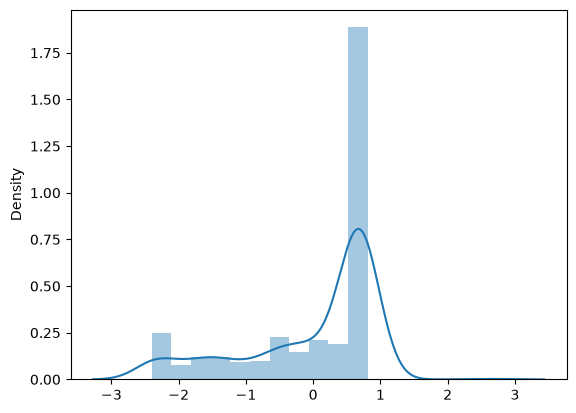

In [14]:
stdNBgraph(dataset["Motor_Temperature_C"])
